# ML1 - GridSearch with DecisionTreeRegressor, RandomForestRegressor

This notebook follows the ML1_Pipeline_Model notebook and focuses on:
1. Using DecisionTreeRegressor and RandomForestRegressor (or others)  
2. Hyperparameter tuning with GridSearchCV  
3. Cross-validation

## 1. Importing Libraries

In [2]:
%conda install pandas numpy scikit-learn seaborn matplotlib


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso 
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV

2 channel Terms of Service accepted
Retrieving notices: done
Channel: defaults
Platform: linux-64
Target prefix: /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/envs/sklearn-env
Solving environment: failed

RattlerUnsatisfiableError: Cannot solve the request because of: The following packages are incompatible
└─ scikit-learn * can be installed with any of the following options:
   ├─ scikit-learn 1.7.2 | 1.8.0 | 1.9.0 | 1.9.1 would require
   │  └─ python >=3.14,<3.15.0a0, which can be installed with any of the following options:
   │     └─ python 3.14.0 | 3.14.1 | ... | 3.14.10
   ├─ scikit-learn 1.5.2 | 1.6.1 | ... | 1.9.1 would require
   │  └─ python >=3.13,<3.14.0a0, which can be installed with any of the following options:
   │     └─ python 3.13.0 | 3.13.1 | ... | 3.13.18
   ├─ scikit-learn 1.3.0 | 1.4.2 | ... | 1.9.1 would require
   │  └─ python >=3.12,<3.13.0a0, which can be installed with any of the following options:
   │     └─ python 3.12.0 | 3.12.1 | ... | 3.12.1

## 2. Loading and Preparing Data with the Pipeline

We follow the same preparation steps as in the previous notebook.


In [3]:
# Load the data from the pickle file.
df = pd.read_pickle('arbres_clean_Alexia.pkl')
df.dropna(subset=['anneedeplantation'], inplace=True)

#Prepare the train and test sets
X = df.drop(columns=['anneedeplantation'])
y = df['anneedeplantation']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=20)

categorical_variables = X_train.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numerical_variables = X_train.select_dtypes(include = ['number']).columns.tolist()
print(categorical_variables,numerical_variables)

#pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)])
	
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

['sous_categorie_desc', 'code_parent_desc', 'adr_secteur', 'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'remarques', 'raisondeplantation', 'traitementchenilles', 'identifiantplu', 'typeimplantationplu', 'intituleprotectionplu', 'collectivite', 'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme', 'typenature'] ['latitude', 'longitude']


/tmp/ipykernel_19129/307231146.py:3: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['anneedeplantation'], inplace=True)


## 3. Initial Cross-Validation

Before tuning hyperparameters, let's evaluate a model with default parameters using cross-validation.


In [4]:
# Initial cross-validation without hyperparameter tuning  
# We can also print the MSE or MAE scores from each cross-validation fold.

model_linear = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])
arbres_scores = cross_val_score(model_linear, X_train, y_train, cv = 5, scoring='neg_root_mean_squared_error') 

print("RMSE moyen :", np.mean(-arbres_scores))
print("RMSE écart-type moyen :", np.std(-arbres_scores))

RMSE moyen : 9.131060977371884
RMSE écart-type moyen : 0.2616323613716188


## 4. 🌳 Modeling with GridSearchCV

Let's choose two machine learning models.

Evaluate the models with hyperparameter tuning (testing different hyperparameter values).  
Optimize the models as you wish, for example for Decision Tree and Random Forest:

### 🔍 Hyperparameters Tested
- `max_depth`: maximum depth of the trees [3, 4, 5, 10]  
- `min_samples_leaf`: minimum number of samples required at a leaf [0.1, 0.05]  
- `n_estimators` (for Random Forest only): number of trees in the forest [50, 100, 200]

Let's use GridSearchCV to automate the search for the best hyperparameters.

In [5]:
# Hyperparameter tuning with GridSearchCV, and we can print the MSE or MAE scores for each cross-validation fold.
model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=10, max_iter=10000))
])

param_grid = [
 {'regression__alpha': [0.001, 0.01, 0.1, 1, 3, 10, 100, 1000]}
 ]

#arbres_scores_lasso = cross_val_score(model_lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
arbres_grid_search = GridSearchCV(model_lasso, param_grid, cv=10, scoring='neg_root_mean_squared_error')
arbres_grid_search.fit(X_train, y_train)

arbres_grid_results = pd.DataFrame(arbres_grid_search.cv_results_)

print(arbres_grid_results)
print(arbres_grid_search.best_estimator_)

#moyenne des rmse pour le meilleur alpha --> répond à la question de k-fold, pour le meilleur alpha
rmse_cv = -arbres_grid_search.best_score_
y_pred_test = arbres_grid_search.predict(X_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

# Comparaison
print("Meilleur alpha :", arbres_grid_search.best_params_)
#estimation erreur de la validation croisée (k-fold)
print("RMSE validation croisée :", rmse_cv)
#estimation erreur réelle sur le jeu de test
print("RMSE test :", rmse_test)
#Pour info, différence entre les deux
print("Différence RMSE :", rmse_test - rmse_cv)

lasso_best = arbres_grid_search.best_estimator_

   mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0       0.960640      0.213396         0.010552        0.000111   
1       0.313609      0.020273         0.010839        0.001106   
2       0.106961      0.002441         0.011207        0.002406   
3       0.090746      0.001836         0.010582        0.000669   
4       0.081324      0.000831         0.010277        0.000120   
5       0.080397      0.000899         0.010854        0.001082   
6       0.080055      0.000372         0.010347        0.000122   
7       0.081102      0.001107         0.010504        0.000246   

   param_regression__alpha                        params  split0_test_score  \
0                    0.001  {'regression__alpha': 0.001}          -8.842194   
1                    0.010   {'regression__alpha': 0.01}          -9.447353   
2                    0.100    {'regression__alpha': 0.1}         -11.333517   
3                    1.000      {'regression__alpha': 1}         -13.766829   
4

In [6]:
# tuning random forest hyperparameters

# select a subset of the data for faster experimentation
X_train_sub = X_train.sample(frac=0.2, random_state=42)
y_train_sub = y_train.loc[X_train_sub.index]

# run one random forest with usual default hyperparameters for comparison
from sklearn.ensemble import RandomForestRegressor
model_rf_default = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])
model_rf_default.fit(X_train_sub, y_train_sub)
y_pred_default = model_rf_default.predict(X_train_sub)


In [7]:

from sklearn.metrics import root_mean_squared_error, mean_absolute_error
print("RMSE for default random forest on training subset:", root_mean_squared_error(y_train_sub, y_pred_default))
print("MAE for default random forest on training subset:", mean_absolute_error(y_train_sub, y_pred_default))


y_pred_test = model_rf_default.predict(X_test)
print("RMSE for default random forest on test subset:", root_mean_squared_error(y_test, y_pred_test))
print("MAE for default random forest on test subset:", mean_absolute_error(y_test, y_pred_test))

RMSE for default random forest on training subset: 2.79587233252822
MAE for default random forest on training subset: 1.4270851207947575
RMSE for default random forest on test subset: 7.774828468071706
MAE for default random forest on test subset: 4.024378217285286


In [8]:

# Hyperparameter tuning with GridSearchCV, and we can print the MSE or MAE scores for each cross-validation fold.
from sklearn.ensemble import RandomForestRegressor


model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])

param_grid = [
 {'regression__n_estimators': [100, 200, 300],
  'regression__min_samples_leaf': [0.05, 0.1, 1, 10],
  'regression__max_depth': [None, 10, 20],
  'regression__random_state': [42]} 
 ]

#arbres_scores_lasso = cross_val_score(model_lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
arbres_grid_search = GridSearchCV(model_random_forest, param_grid, cv=10, scoring='neg_root_mean_squared_error')
arbres_grid_search.fit(X_train_sub, y_train_sub)

arbres_grid_results = pd.DataFrame(arbres_grid_search.cv_results_)

print(arbres_grid_results)
print(arbres_grid_search.best_estimator_)


KeyboardInterrupt: 

In [24]:

#moyenne des rmse pour la meilleure combinaison de parametres --> répond à la question de k-fold, pour le meilleur alpha
rmse_cv = -arbres_grid_search.best_score_
y_pred_test = arbres_grid_search.predict(X_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

print("RMSE validation croisée :", rmse_cv)
print("RMSE test :", rmse_test)
print("Différence RMSE :", rmse_test - rmse_cv)
print("Meilleure combinaison de parametres :", arbres_grid_search.best_params_)


RMSE validation croisée : 9.01143782658554
RMSE test : 8.683307942212469
Différence RMSE : -0.32812988437307133
Meilleure combinaison de parametres : {'regression__max_depth': None, 'regression__min_samples_leaf': 1, 'regression__n_estimators': 100, 'regression__random_state': 42}


In [ ]:
# autre facon de faire le tuning, avec randomGridSearch

from sklearn.model_selection import RandomizedSearchCV

# define the parameter grid for random search
param_distributions = {
    'regression__n_estimators': [100, 200, 300, 400, 500],
    'regression__max_depth': [None, 10, 20, 30, 40, 50],
    'regression__min_samples_split': [2, 5, 10],
    'regression__min_samples_leaf': [1, 2, 4],
    'regression__max_features': ['auto', 'sqrt', 'log2'],
    'regression__bootstrap': [True, False]
}

random_search = RandomizedSearchCV(
    estimator=model_random_forest,
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    scoring='neg_mean_squared_error',
    verbose=2,
    random_state=42,
    n_jobs=-1
)

arbre_random_search = random_search.fit(X_train_sub, y_train_sub)
print(f"Best parameters found: {arbre_random_search.best_params_}")
print(f"Best score found: {arbre_random_search.best_score_}")

# get the best model from the random search
best_model = arbre_random_search.best_estimator_
y_pred_best = best_model.predict(X_train_sub)
from sklearn.metrics import mean_squared_error
mse_best = mean_squared_error(y_train_sub, y_pred_best)
print(f"Mean Squared Error of the best model: {mse_best}")

# compare with the default model
y_pred_default = model_rf_default.predict(X_train_sub)
mse_default = mean_squared_error(y_train_sub, y_pred_default)
print(f"Mean Squared Error of the default model: {mse_default}")

# compare with the random search best model
print(f"Improvement: {mse_default - mse_best}")
print(f"Percentage improvement: {(mse_default - mse_best) / mse_default * 100:.2f}%")



Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END regression__bootstrap=True, regression__max_depth=10, regression__max_features=auto, regression__min_samples_leaf=1, regression__min_samples_split=2, regression__n_estimators=100; total time=   0.1s
[CV] END regression__bootstrap=True, regression__max_depth=10, regression__max_features=auto, regression__min_samples_leaf=1, regression__min_samples_split=2, regression__n_estimators=100; total time=   0.1s
[CV] END regression__bootstrap=True, regression__max_depth=10, regression__max_features=auto, regression__min_samples_leaf=1, regression__min_samples_split=2, regression__n_estimators=100; total time=   0.1s
[CV] END regression__bootstrap=True, regression__max_depth=10, regression__max_features=auto, regression__min_samples_leaf=1, regression__min_samples_split=2, regression__n_estimators=100; total time=   0.1s
[CV] END regression__bootstrap=True, regression__max_depth=40, regression__max_features=auto, regression__

/home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/envs/sklearn-env/lib/python3.15/site-packages/sklearn/model_selection/_validation.py:493: FitFailedWarning: 
115 fits failed out of a total of 250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
66 fits failed with the following error:
Traceback (most recent call last):
  File "/home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/envs/sklearn-env/lib/python3.15/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/envs/sklearn-env/lib/python3.15/site-packages/sklearn/base.py", line 1403, in w

Best parameters found: {'regression__n_estimators': 100, 'regression__min_samples_split': 2, 'regression__min_samples_leaf': 1, 'regression__max_features': 'sqrt', 'regression__max_depth': 30, 'regression__bootstrap': True}
Best score found: 0.8021408776108615
Mean Squared Error of the best model: 14.86317398482095
Mean Squared Error of the default model: 7.81690209979679
Improvement: -7.04627188502416
Percentage improvement: -90.14%


In [ ]:
# tuning the randomforest on the whole test set with best hyperparameters
from sklearn.ensemble import RandomForestRegressor

model_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(**best_params_rf))
])
model_rf.fit(X_train, y_train)
y_pred_train = model_rf.predict(X_train)
print("RMSE for tuned random forest on training set:", root_mean_squared_error(y_train, y_pred_train))
print("MAE for tuned random forest on training set:", mean_absolute_error(y_train, y_pred_train))

# Comparaison
y_pred_test = model_rf.predict(X_test)
print("RMSE for tuned random forest on test set:", root_mean_squared_error(y_test, y_pred_test))
print("MAE for tuned random forest on test set:", mean_absolute_error(y_test, y_pred_test))



Meilleure combinaison de parametres : {'regression__max_depth': None, 'regression__min_samples_leaf': 0.01, 'regression__n_estimators': 100}
RMSE validation croisée : 11.424625020700725
RMSE test : 11.490952024599752
Différence RMSE : 0.06632700389902624


In [25]:

print("Best model: ")
print(arbres_grid_search.best_params_)
random_forest_best = arbres_grid_search.best_params_

Best model: 
{'regression__max_depth': None, 'regression__min_samples_leaf': 1, 'regression__n_estimators': 100, 'regression__random_state': 42}


In [ ]:
# modeles avec best hyperparameter tuning

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
import numpy as np

model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(**lasso_best.get_params()['regression']))
])

model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(**random_forest_best.get_params()['regression']))
])

# model_decision_tree = Pipeline([
#     ('preprocessor', preprocessor),
#     ('regression', DecisionTreeRegressor())
# ])

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}


models = {
    'LinearRegression': model_linear,
    'Lasso': model_lasso,
    'RandomForest': model_random_forest,
    #'DecisionTree': model_decision_tree
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    rmse = -scores['test_rmse']
    mae = -scores['test_mae']
    r2 = scores['test_r2']

    # rmse = np.sqrt(mse)  # Not needed anymore since 'mse' is already RMSE

    print(f"\n{name}")
    print(f"RMSE moyen : {rmse.mean():.2f}")
    print(f"RMSE écart-type : {rmse.std():.2f}")
    print(f"MAE moyen  : {mae.mean():.2f}")
    print(f"R² moyen   : {r2.mean():.3f}")
    print(f"Écart-type MAE : {mae.std():.2f}")
    print(f"Écart-type R² : {r2.std():.3f}")
    print(f"Écart-type RMSE : {rmse.std():.2f}")
    print(f"RMSE min : {rmse.min():.2f}")
    print(f"RMSE max : {rmse.max():.2f}")
    print(f"MAE min : {mae.min():.2f}")
    print(f"MAE max : {mae.max():.2f}")
    print(f"R² min : {r2.min():.3f}")
    print(f"R² max : {r2.max():.3f}")


LinearRegression
RMSE moyen : 9.13
RMSE écart-type : 0.26
MAE moyen  : 6.46
R² moyen   : 0.746
Écart-type MAE : 0.11
Écart-type R² : 0.011
Écart-type RMSE : 0.26
RMSE min : 8.78
RMSE max : 9.48
MAE min : 6.28
MAE max : 6.61
R² min : 0.732
R² max : 0.760

Lasso
RMSE moyen : 9.13
RMSE écart-type : 0.27
MAE moyen  : 6.49
R² moyen   : 0.746
Écart-type MAE : 0.11
Écart-type R² : 0.012
Écart-type RMSE : 0.27
RMSE min : 8.77
RMSE max : 9.49
MAE min : 6.30
MAE max : 6.64
R² min : 0.732
R² max : 0.760


## 5. Final Evaluation on the Test Set

In [12]:
# Code for evaluating the best model on the test set.

from sklearn.model_selection import cross_validate
import numpy as np

model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=0.001, max_iter=10000))
])

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

# Tes deux modèles Pipeline, déjà définis
models = {
    'LinearRegression': model_linear,
    'Lasso': model_lasso
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_test,
        y_test,
        cv=5,
        scoring=scoring
    )

    rmse = -scores['test_rmse']
    mae = -scores['test_mae']
    r2 = scores['test_r2']

    # rmse = np.sqrt(mse)  # Not needed anymore since 'mse' is already RMSE

    print(f"\n{name}")
    print(f"RMSE moyen : {rmse.mean():.2f}")
    print(f"RMSE écart-type : {rmse.std():.2f}")
    print(f"MAE moyen  : {mae.mean():.2f}")
    print(f"R² moyen   : {r2.mean():.3f}")
    print(f"Écart-type MAE : {mae.std():.2f}")
    print(f"Écart-type R² : {r2.std():.3f}")
    print(f"Écart-type RMSE : {rmse.std():.2f}")
    print(f"RMSE min : {rmse.min():.2f}")
    print(f"RMSE max : {rmse.max():.2f}")
    print(f"MAE min : {mae.min():.2f}")
    print(f"MAE max : {mae.max():.2f}")
    print(f"R² min : {r2.min():.3f}")
    print(f"R² max : {r2.max():.3f}")


LinearRegression
RMSE moyen : 9.66
RMSE écart-type : 0.23
MAE moyen  : 6.73
R² moyen   : 0.722
Écart-type MAE : 0.14
Écart-type R² : 0.011
Écart-type RMSE : 0.23
RMSE min : 9.24
RMSE max : 9.93
MAE min : 6.59
MAE max : 6.95
R² min : 0.707
R² max : 0.734

Lasso
RMSE moyen : 9.61
RMSE écart-type : 0.26
MAE moyen  : 6.73
R² moyen   : 0.725
Écart-type MAE : 0.14
Écart-type R² : 0.012
Écart-type RMSE : 0.26
RMSE min : 9.14
RMSE max : 9.89
MAE min : 6.57
MAE max : 6.96
R² min : 0.710
R² max : 0.739


## 6. Visualization of Predictions  
One model will suffice.

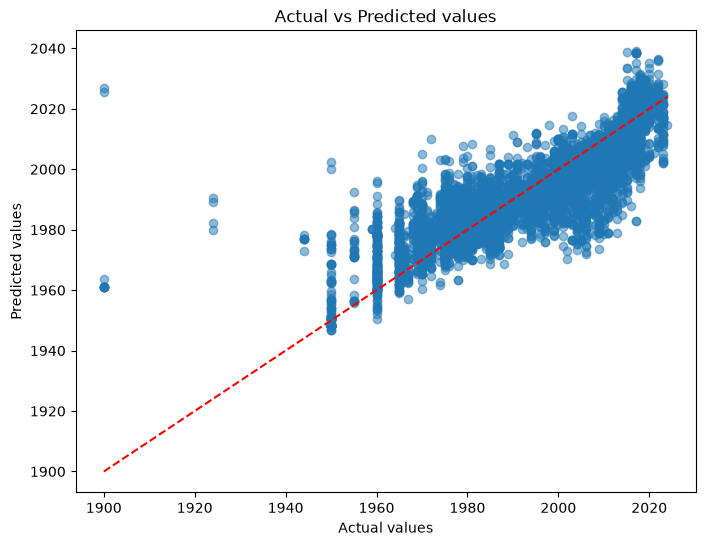

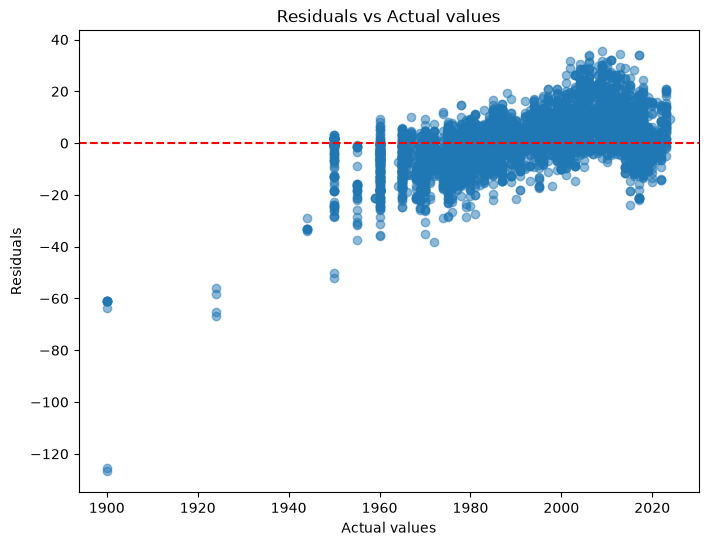

In [14]:
model = model_lasso

model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Visualisation of predictions.

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test, alpha=0.5)

# Línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted values')
plt.show()

# Visualisation of residuals.
residuals = y_test - y_pred_test
plt.figure(figsize=(8, 6))
plt.scatter(y_test, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Actual values')
plt.ylabel('Residuals')
plt.title('Residuals vs Actual values')
plt.show()



## [OPTIONAL] 7.Feature Importance

Using the random forest, how can we determine which features are the most important?

In [ ]:
# Code. In your opinion, how is feature importance calculated in Random Forest?

Typically, one might consider using backward elimination on feature importance to select the best subset of features, but this can be time-consuming if there are many features and the model takes a while to train, as is the case here. Instead, we can use Lasso-regularized regression to eliminate features, before retraining a RandomForest on the selected features. Create a pipeline with `LassoCV` as the selector and a RandomForest as the model with the best hyperparameters found by the previous grid-search. Evaluate on the test set.

In [ ]:
# Code

## 8. [OPTIONAL]  Compare more different models

Compare more regression models with one another (for example, in addition to linear regression, decision trees, and forests, use `GradientBoostingRegressor`, and the novel `TabICLRegressor` if you have time ( https://github.com/soda-inria/tabicl ))), by performing appropriate hyperparameter tuning for each model:

In [ ]:
# Code. Search which hyper-parameters are worth tuning for each model

Choose the model that performs best and its optimal hyperparameters, then select the best subset of features for this model, and finally perform one last grid search on your model’s hyperparameters using the selected features to obtain your final model. Evaluate it on the test set.

In [ ]:
# Code

## Conclusion